# Логистическая регрессия и показатели ошибок классификации
![LogRegr.png](Assets/LogRegr.png)


# Цели обучения

- Описать логистическую регрессию и её отличия от линейной регрессии
- Определить метрики ошибок классификации и сценарии, в которых их можно использовать
- Применять расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения



## Введение

Мы будем использовать базу данных [«Распознавание человеческой активности с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), которая была сформирована на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [1]:
from __future__ import print_function
import os
data_path = []   # файл лежит рядом с ноутбуком

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import precision_recall_fscore_support as score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

# Intel-расширение необязательно: без него работает обычный scikit-learn
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex не установлен - используется стандартный scikit-learn')

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

Импортируйте данные и выполните следующие действия:

* Проанализируйте типы данных — столбцов много, поэтому целесообразно использовать подсчёт значений
* Определите, требуется ли масштабирование значений с плавающей запятой
* Определите структуру каждого вида деятельности
* Кодируйте название вида деятельности в виде целого числа

In [2]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')

Все столбцы данных содержат числа типа float, за исключением метки активности.

In [3]:
data.dtypes.value_counts()

float64    561
str          1
Name: count, dtype: int64

In [4]:
data.dtypes.tail()

angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Activity                                    str
dtype: object

Все данные приведены к шкале от -1 (минимум) до 1,0 (максимум).

In [5]:
data.iloc[:, :-1].min().value_counts()

-1.0    561
Name: count, dtype: int64

In [6]:
data.iloc[:, :-1].max().value_counts()

1.0    561
Name: count, dtype: int64

Проанализируйте структуру мероприятий — они относительно сбалансированы.

In [7]:
data.Activity.value_counts()

Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

Классификаторы Scikit-learn не принимают разреженные матрицы в качестве столбца для прогнозирования. Поэтому необходимо либо использовать `LabelEncoder` для преобразования меток активности в целые числа, либо, если используется `DictVectorizer`, преобразовать результирующую матрицу в неразреженный массив.
Используйте `LabelEncoder` для преобразования столбца «Activity» с помощью `fit_transform` и просмотрите 5 случайных значений.

In [8]:
le = LabelEncoder()
data['Activity'] = le.fit_transform(data.Activity)
data['Activity'].sample(5)

1472    5
5182    3
50      1
2562    2
3324    0
Name: Activity, dtype: int64

## Вопрос 2

* Рассчитайте коэффициенты корреляции между зависимыми переменными.
* Постройте гистограмму значений коэффициентов корреляции.
* Определите, какие из них наиболее сильно коррелируют (положительно или отрицательно).

In [9]:
# Calculate the correlation values
feature_cols = data.columns[:-1]
corr_values = data[feature_cols].corr()

# Simplify by emptying all the data below the diagonal (включая диагональ)
upper = np.triu(np.ones(corr_values.shape, dtype=bool), k=1)
corr_values = corr_values.where(upper)

# Stack the data and convert to a data frame
corr_values = (corr_values
               .stack()
               .to_frame()
               .reset_index()
               .rename(columns={'level_0':'feature1',
                                'level_1':'feature2',
                                0:'correlation'}))

# Get the absolute values for sorting
corr_values['abs_correlation'] = corr_values.correlation.abs()

Гистограмма корреляций по абсолютным значениям.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

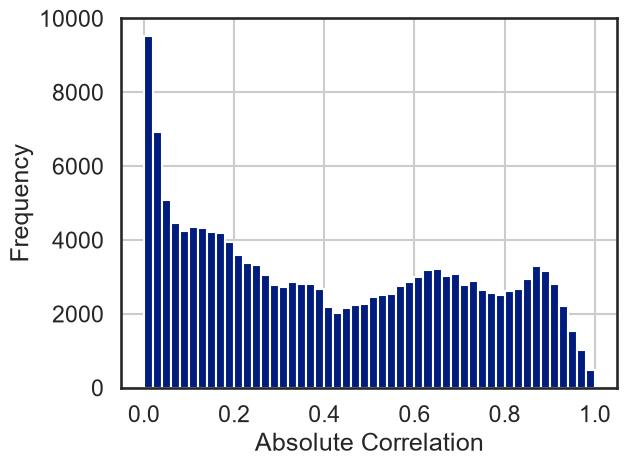

In [11]:
sns.set_context('talk')
sns.set_style('white')
sns.set_palette('dark')

ax = corr_values.abs_correlation.hist(bins=50)

ax.set(xlabel='Absolute Correlation', ylabel='Frequency');

In [12]:
# The most highly correlated values
corr_values.sort_values('correlation', ascending=False).query('abs_correlation>0.8')

,feature1,feature2,correlation,abs_correlation
304047,fBodyBodyGyroJerkMag-mean(),fBodyBodyGyroJerkMag-sma(),1.000000,1.000000
296741,fBodyBodyGyroMag-mean(),fBodyBodyGyroMag-sma(),1.000000,1.000000
119711,tGravityAccMag-mean(),tGravityAccMag-sma(),1.000000,1.000000
119157,tBodyAccMag-arCoeff()4,tGravityAccMag-arCoeff()4,1.000000,1.000000
141629,tBodyGyroJerkMag-mean(),tBodyGyroJerkMag-sma(),1.000000,1.000000
...,...,...,...,...
23560,tGravityAcc-mean()-Y,"angle(Y,gravityMean)",-0.993425,0.993425
42151,"tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4",-0.994267,0.994267
41589,"tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3",-0.994628,0.994628
24122,tGravityAcc-mean()-Z,"angle(Z,gravityMean)",-0.994764,0.994764


**Вывод (вопрос 2).** Среди 561 признака много почти идеально коррелирующих пар (коэффициент до 1,0), например `tBodyAccMag-min()` и `tGravityAccMag-min()`, а также пары `mean`/`sma` одного и того же сигнала. Сильные отрицательные корреляции (около −0,99) встречаются у координат гравитации и соответствующих углов, например `tGravityAcc-mean()-Z` и `angle(Z,gravityMean)`. Значит, признаки сильно избыточны, и регуляризация здесь оправдана.

## Вопрос 3

* Разделите данные на обучающий и тестовый наборы. Это можно сделать любым способом, но рекомендуется использовать метод `StratifiedShuffleSplit` из библиотеки Scikit-learn, чтобы сохранить одинаковое соотношение классов предикторов.
* Независимо от метода, использованного для разделения данных, сравните соотношение классов в обучающем и тестовом наборах.


In [13]:
# Get the split indexes
strat_shuf_split = StratifiedShuffleSplit(n_splits=1,
                                          test_size=0.3,
                                          random_state=42)

train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data.Activity))

# Create the dataframes
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'Activity']

X_test  = data.loc[test_idx, feature_cols]
y_test  = data.loc[test_idx, 'Activity']

In [14]:
y_train.value_counts(normalize=True)

Activity
0    0.188792
2    0.185046
1    0.172562
3    0.167152
5    0.149951
4    0.136496
Name: proportion, dtype: float64

In [15]:
y_test.value_counts(normalize=True)

Activity
0    0.188673
2    0.185113
1    0.172492
3    0.167314
5    0.149838
4    0.136570
Name: proportion, dtype: float64

## Вопрос 4

* Постройте модель логистической регрессии без какой-либо регуляризации с использованием всех признаков. Обязательно ознакомьтесь с документацией по построению многоклассовых моделей, чтобы понять, как интерпретировать выведенные коэффициенты. Сохраните модель.
* Используя перекрестную валидацию для определения гиперпараметров, постройте модели с L1- и L2-регуляризацией. Сохраните также каждую из этих моделей. Обратите внимание на ограничения, связанные с многоклассовыми моделями, решателями и видами регуляризации. Построение регуляризованных моделей, в частности модели с L1-регуляризацией, вероятно, займет некоторое время.

In [16]:
# Standard logistic regression: БЕЗ регуляризации (C=inf)
lr = LogisticRegression(C=np.inf, max_iter=295).fit(X_train, y_train)

c:\Users\User\Downloads\lab_5_ml\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 295 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=295).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [17]:
# L1 regularized logistic regression
# liblinear в новых версиях scikit-learn не поддерживает многоклассовую задачу,
# поэтому используем solver='saga' (l1_ratios=[1] означает чистую L1-регуляризацию)
lr_l1 = LogisticRegressionCV(Cs=10, cv=4, l1_ratios=[1], solver='saga',
                             max_iter=300, tol=1e-3, n_jobs=-1).fit(X_train, y_train)

c:\Users\User\Downloads\lab_5_ml\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
c:\Users\User\Downloads\lab_5_ml\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


In [18]:
# L2 regularized logistic regression
lr_l2 = LogisticRegressionCV(Cs=10, cv=4, l1_ratios=[0], max_iter=500, n_jobs=-1).fit(X_train, y_train)

c:\Users\User\Downloads\lab_5_ml\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
c:\Users\User\Downloads\lab_5_ml\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


## Вопрос 5

Сравните величины коэффициентов для каждой из моделей. Если использовалась подстановка «один против остальных», каждый набор коэффициентов можно отобразить на графике отдельно.

In [19]:
# Combine all the coefficients into a dataframe
coefficients = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]

for lab,mod in zip(coeff_labels, coeff_models):
    coeffs = mod.coef_
    coeff_label = pd.MultiIndex(levels=[[lab], [0,1,2,3,4,5]],
                                codes=[[0,0,0,0,0,0], [0,1,2,3,4,5]])
    coefficients.append(pd.DataFrame(coeffs.T, columns=coeff_label))

coefficients = pd.concat(coefficients, axis=1)

coefficients.sample(10)

lr                                                            l1  \
            0         1         2          3         4          5         0   
216 -0.323205 -5.647523  0.262595  -2.519176  4.994229   3.233079  0.026299   
488 -0.640701  0.286303  1.295051   1.334063 -2.883517   0.608801 -0.024103   
387 -0.282094  0.406024  1.912148  -0.769318  2.254340  -3.521101 -0.034482   
177 -0.298725  0.251773  2.184659  -2.082638  1.489493  -1.544562 -0.034378   
81  -1.024513 -4.799955  4.212982  -0.075828  0.487901   1.199411 -0.029378   
312 -0.352862 -0.147963  1.665754  -3.180926  2.407071  -0.391074 -0.021728   
221 -3.066634 -4.059045 -6.513218   4.085476  5.963812   3.589610  0.001656   
117  0.853769  0.398913  1.934400  13.923132  1.235348 -18.345562 -0.009694   
142 -0.241029 -9.131293  4.889486   3.246187  6.577878  -5.341230 -0.004461   
253 -1.324420 -3.466038  2.740185   1.379027  1.709083  -1.037836 -0.026041   

                                                                 l2            \
            1         2             3         4         5         0         1   
216 -0.079970  0.018623 -1.432111e-01  0.105407  0.070182  0.071380 -0.847524   
488 -0.000290  0.025929  8.014839e-02 -0.111573  0.024553 -0.115776 -0.030152   
387 -0.002539  0.048685  4.308502e-03  0.073650 -0.065842 -0.125683 -0.017677   
177 -0.005905  0.082429 -1.063439e-02  0.034755 -0.027185 -0.124932 -0.035293   
81  -0.050901  0.081928  2.251049e-02  0.015530 -0.024284 -0.092651 -1.013952   
312 -0.008333  0.045760 -8.269877e-02  0.120227 -0.000716 -0.114569 -0.088701   
221  0.004326 -0.666412 -9.833653e-07  0.064674  0.003073  0.031465  0.226645   
117  0.024041  0.109072  7.456356e-01  0.145308 -2.186307 -0.062687  0.155703   
142 -1.506110  0.983310  8.248414e-02  0.289570 -0.679464 -0.077252 -1.674661   
253 -0.101119  0.215830  1.560647e-02  0.036552 -0.064285 -0.119451 -0.683511   

                                             
            2         3         4         5  
216  0.484901 -0.791906  0.741774  0.341375  
488  0.183631  0.242991 -0.489433  0.208740  
387  0.220636  0.015905  0.169448 -0.262629  
177  0.259515 -0.153501  0.156063 -0.101852  
81   1.100385 -0.140272  0.112629  0.033860  
312  0.233455 -0.333966  0.341942 -0.038161  
221 -0.854903  0.133663  0.308653  0.154477  
117  0.146200  1.688659  0.302305 -2.230179  
142  1.719657  0.224947  0.841670 -1.034361  
253  0.766372  0.106940  0.147435 -0.217784

Подготовьте шесть отдельных графиков для каждого из многоклассовых коэффициентов.

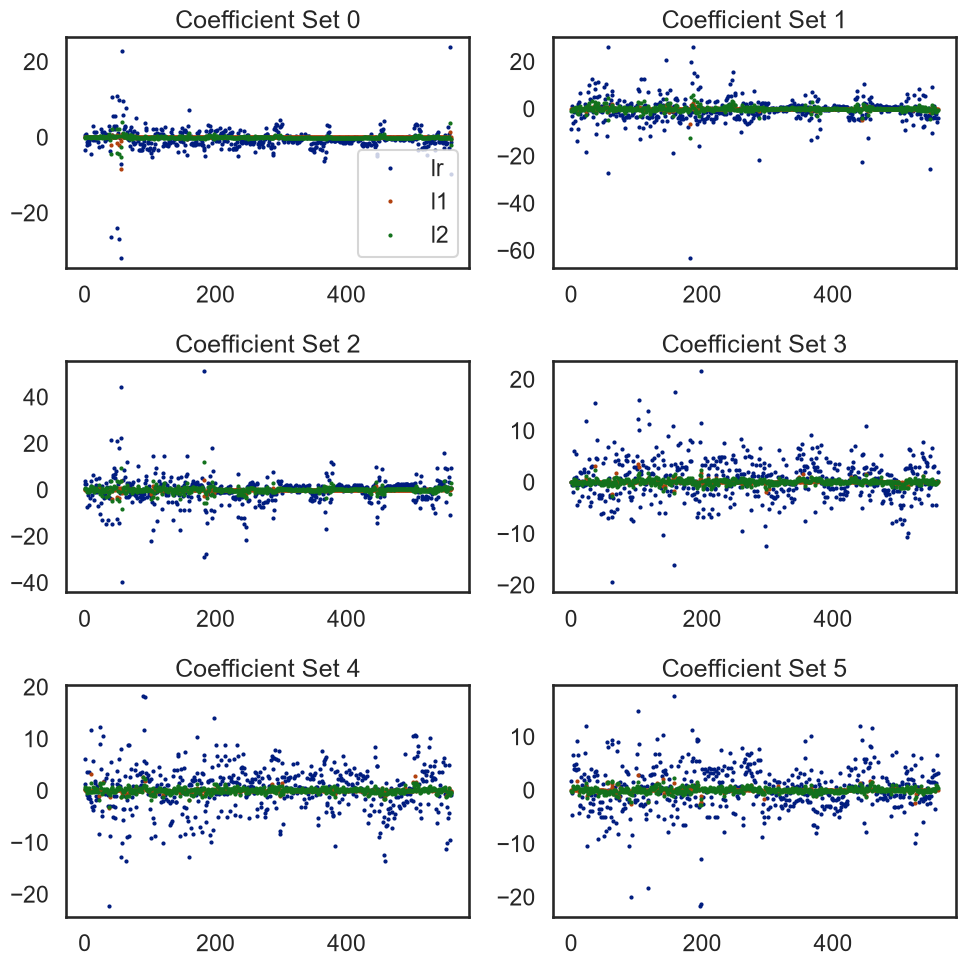

In [20]:
fig, axList = plt.subplots(nrows=3, ncols=2)
axList = axList.flatten()
fig.set_size_inches(10,10)

for ax in enumerate(axList):
    loc = ax[0]
    ax = ax[1]

    coef_data = coefficients.xs(loc, level=1, axis=1)
    coef_data.plot(marker='o', ls='', ms=2.0, ax=ax, legend=False)

    if ax is axList[0]:
        ax.legend(loc=4)

    ax.set(title='Coefficient Set '+str(loc))

plt.tight_layout()

## Вопрос 6

* Определите и сохраните класс для каждой модели.
* Также сохраните вероятность для предсказанного класса для каждой модели.

In [21]:
# Predict the class and the probability for each
y_pred = list()
y_prob = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]

for lab,mod in zip(coeff_labels, coeff_models):
    y_pred.append(pd.Series(mod.predict(X_test), name=lab))
    y_prob.append(pd.Series(mod.predict_proba(X_test).max(axis=1), name=lab))

y_pred = pd.concat(y_pred, axis=1)
y_prob = pd.concat(y_prob, axis=1)

y_pred.head()

,lr,l1,l2
0,3,3,3
1,5,5,5
2,3,3,3
3,1,1,1
4,0,0,0


In [22]:
y_prob.head()

,lr,l1,l2
0,1.0,0.999999,1.000000
1,1.0,0.999854,0.999998
2,1.0,0.999596,0.999979
3,1.0,0.998554,0.999996
4,1.0,0.998906,0.999986


## Вопрос 7

Для каждой модели рассчитайте следующие показатели ошибок:

* точность
* прецизионность
* полнота
* F-показатель
* матрица путаницы

Определите, как объединить показатели для нескольких классов в одно значение для каждой модели.

In [23]:
metrics = list()
cm = dict()

for lab in coeff_labels:

    # Preciision, recall, f-score from the multi-class support function
    precision, recall, fscore, _ = score(y_test, y_pred[lab], average='weighted')

    # The usual way to calculate accuracy
    accuracy = accuracy_score(y_test, y_pred[lab])

    # ROC-AUC scores can be calculated by binarizing the data
    auc = roc_auc_score(label_binarize(y_test, classes=[0,1,2,3,4,5]),
              label_binarize(y_pred[lab], classes=[0,1,2,3,4,5]),
              average='weighted')

    # Last, the confusion matrix
    cm[lab] = confusion_matrix(y_test, y_pred[lab])

    metrics.append(pd.Series({'precision':precision, 'recall':recall,
                              'fscore':fscore, 'accuracy':accuracy,
                              'auc':auc},
                             name=lab))

metrics = pd.concat(metrics, axis=1)

In [24]:
metrics

,lr,l1,l2
precision,0.978957,0.983810,0.985118
recall,0.978964,0.983819,0.985113
fscore,0.978953,0.983811,0.985113
accuracy,0.978964,0.983819,0.985113
auc,0.987297,0.990159,0.990961


**Вывод (вопросы 6–7).** Для объединения показателей по шести классам используется взвешенное усреднение (`average='weighted'`): классы почти сбалансированы, а веса пропорциональны числу объектов каждого класса.

| Модель | accuracy | precision | recall | F-мера | AUC |
|---|---|---|---|---|---|
| без регуляризации | 0,9790 | 0,9790 | 0,9790 | 0,9790 | 0,9873 |
| L1 | 0,9838 | 0,9838 | 0,9838 | 0,9838 | 0,9902 |
| L2 | 0,9851 | 0,9851 | 0,9851 | 0,9851 | 0,9910 |

Регуляризованные модели лучше модели без регуляризации, лучшая - L2. Различия небольшие, около 0,5-0,6 процентного пункта: данные хорошо разделимы, а коэффициент регуляризации, подобранный перекрёстной валидацией, оказывается слабым.

## Вопрос 8

Отобразите или постройте матрицу путаницы для каждой модели.

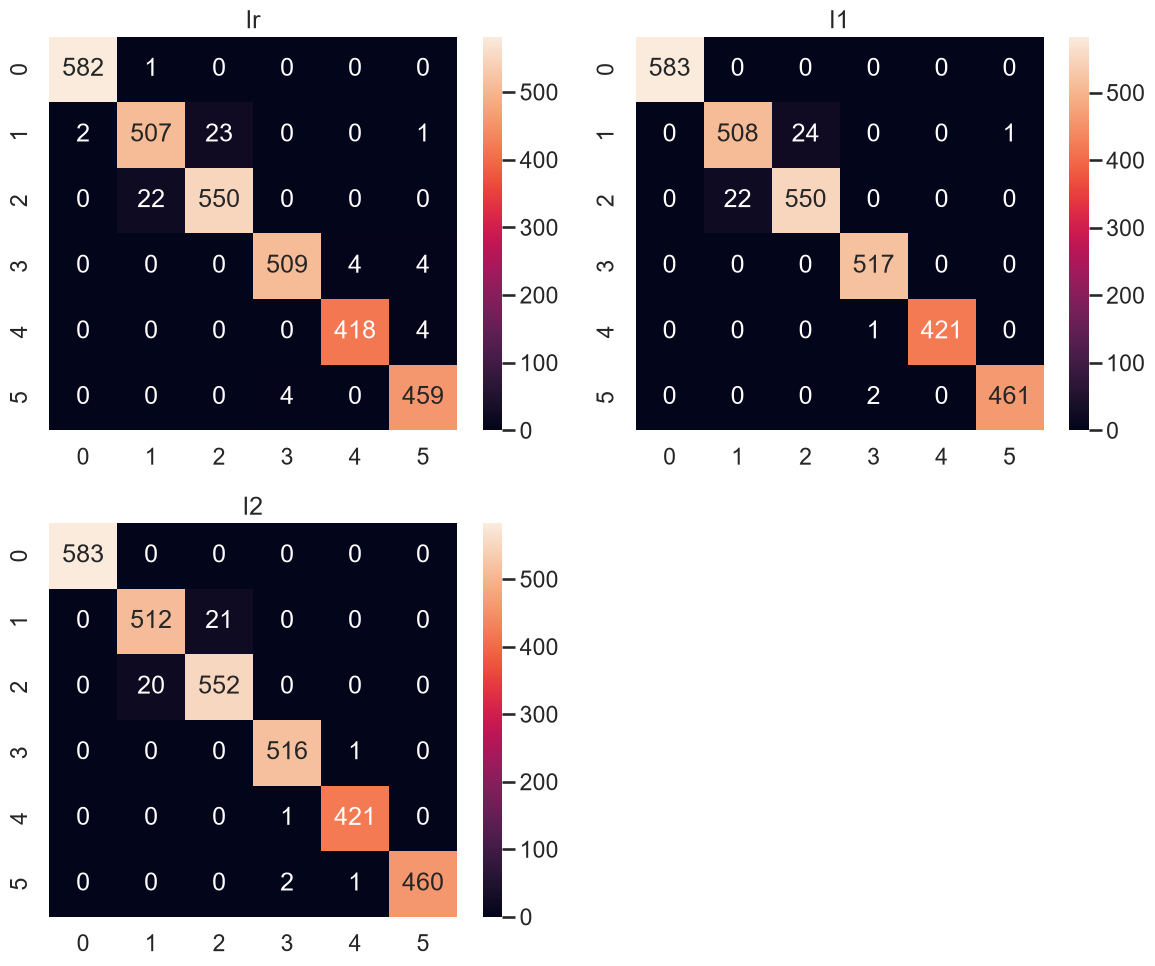

In [25]:
fig, axList = plt.subplots(nrows=2, ncols=2)
axList = axList.flatten()
fig.set_size_inches(12, 10)

axList[-1].axis('off')

for ax,lab in zip(axList[:-1], coeff_labels):
    sns.heatmap(cm[lab], ax=ax, annot=True, fmt='d');
    ax.set(title=lab);

plt.tight_layout()

In [26]:
#493.98 sec

**Вывод (вопрос 8).** Матрицы путаницы всех трёх моделей имеют ярко выраженную диагональ: подавляющее большинство объектов классифицируется верно, что согласуется с точностью около 98%.